In [2]:
import numpy as np
np.set_printoptions(threshold=10000, suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("credit_scoring.csv" , sep = ";")
df.head()

,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price,Status
0,9.0,1.0,60.0,30.0,0.0,1.0,1.0,73.0,129.0,0.0,0.0,800.0,846.0,1
1,17.0,1.0,60.0,58.0,1.0,1.0,0.0,48.0,131.0,0.0,0.0,1000.0,1658.0,1
2,10.0,0.0,36.0,46.0,0.0,2.0,1.0,90.0,200.0,3000.0,0.0,2000.0,2985.0,0
3,0.0,1.0,60.0,24.0,1.0,1.0,0.0,63.0,182.0,2500.0,0.0,900.0,1325.0,1
4,0.0,1.0,36.0,26.0,1.0,1.0,0.0,46.0,107.0,0.0,0.0,310.0,910.0,1


In [4]:
X = df.drop("Status", axis = 1).values
y = df["Status"].values
print ("Type de X : ", type(X))
print ("Type de y : ", type(y))


Type de X :  <class 'numpy.ndarray'>
Type de y :  <class 'numpy.ndarray'>


In [5]:
print ("Taille de X : ", X.shape)
print ("Taille de y : ", y.shape)

positifs = sum (y == 1)
negatifs = sum (y == 0)

print ("\nNombres de personnes ayant fait un crédit (y = 1) : ", positifs)
print ("Nombres de personnes n'ayant pas fait un crédit (y = 0) :", negatifs)

print ("\npourcentage positifs : ", round(positifs / len(y) * 100,2), "%")
print ("pourcentage negatifs : ", round(negatifs / len(y) * 100,2), "%")


Taille de X :  (4375, 13)
Taille de y :  (4375,)

Nombres de personnes ayant fait un crédit (y = 1) :  3159
Nombres de personnes n'ayant pas fait un crédit (y = 0) : 1216

pourcentage positifs :  72.21 %
pourcentage negatifs :  27.79 %


In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=1,
    stratify=y
)

print("Taille X_train :", X_train.shape)
print("Taille X_test  :", X_test.shape)
print("Taille y_train :", y_train.shape)
print("Taille y_test  :", y_test.shape)

import numpy as np

def proportions(label_array): 
    uniques, counts = np.unique(label_array, return_counts=True)
    total = len(label_array)
    return {int(u): round(c/total*100,2) for u, c in zip(uniques, counts)}

print("\nProportions dans y (global) :", proportions(y))
print("Proportions dans y_train     :", proportions(y_train))
print("Proportions dans y_test      :", proportions(y_test))  





Taille X_train : (2187, 13)
Taille X_test  : (2188, 13)
Taille y_train : (2187,)
Taille y_test  : (2188,)

Proportions dans y (global) : {0: np.float64(27.79), 1: np.float64(72.21)}
Proportions dans y_train     : {0: np.float64(27.8), 1: np.float64(72.2)}
Proportions dans y_test      : {0: np.float64(27.79), 1: np.float64(72.21)}


In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Dictionnaire des modèles supervisés
clé = {
    "CART": DecisionTreeClassifier(random_state=1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "MLP": MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
}

clé


{'CART': DecisionTreeClassifier(random_state=1),
 'KNN': KNeighborsClassifier(),
 'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), max_iter=500, random_state=1)}


Entraînement du modèle : CART

Matrice de confusion pour CART :

[[ 297  311]
 [ 319 1261]]


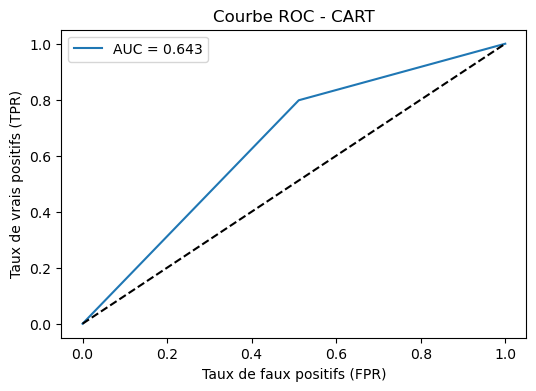

Accuracy  : 0.712
Précision : 0.802
Rappel    : 0.798
Score final = 0.757

Entraînement du modèle : KNN

Matrice de confusion pour KNN :

[[ 180  428]
 [ 221 1359]]


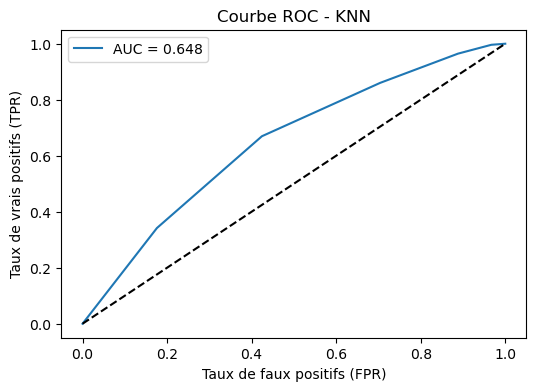

Accuracy  : 0.703
Précision : 0.760
Rappel    : 0.860
Score final = 0.782

Entraînement du modèle : MLP

Matrice de confusion pour MLP :

[[  59  549]
 [  55 1525]]


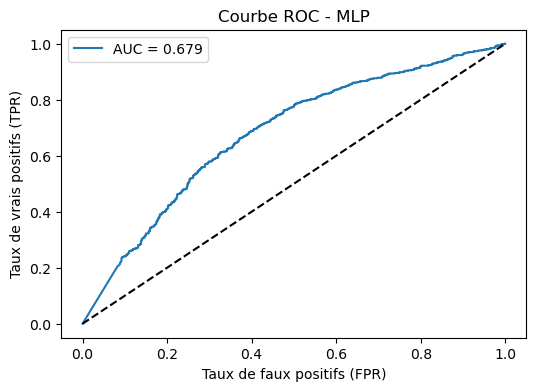

Accuracy  : 0.724
Précision : 0.735
Rappel    : 0.965
Score final = 0.845

##################################################
Meilleur modèle : MLP avec un score de 0.845
##################################################

Scores obtenus :
{'CART': 0.757114331700555, 'KNN': 0.7817543331867725, 'MLP': 0.8445693425589522}

Meilleur modèle entraîné : MLPClassifier(hidden_layer_sizes=(40, 20), max_iter=500, random_state=1)


In [8]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

def evaluation (model , X_test, y_test, model_name = "") : 
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]   
    cm = confusion_matrix(y_test, y_pred)

    print(f"\nMatrice de confusion pour {model_name} :\n")
    print(cm)

    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)

    plt.figure(figsize=(6,4))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0,1], [0,1], 'k--')   # Diagonale du hasard
    plt.xlabel("Taux de faux positifs (FPR)")
    plt.ylabel("Taux de vrais positifs (TPR)")
    plt.title(f"Courbe ROC - {model_name}")
    plt.legend()
    plt.show()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)

    print(f"Accuracy  : {accuracy:.3f}")
    print(f"Précision : {precision:.3f}")
    print(f"Rappel    : {recall:.3f}")

    best = max(precision, recall)
    score_final = (accuracy + best) / 2
    print(f"Score final = {score_final:.3f}")

    return score_final


def run_classifiers_train_test(clé, X_train, X_test, y_train, y_test):
    scores = {}  

    for name, model in clé.items():
        print("\n" + "="*50)
        print(f"Entraînement du modèle : {name}")
        print("="*50)

        
        model.fit(X_train, y_train)

       
        score = evaluation(model, X_test, y_test, model_name=name)

       
        scores[name] = score

    best_name = max(scores, key=scores.get)   
    best_model = clé[best_name]

    print("\n" + "#"*50)
    print(f"Meilleur modèle : {best_name} avec un score de {scores[best_name]:.3f}")
    print("#"*50)

    return best_model, scores


best_model, scores = run_classifiers_train_test(clé, X_train, X_test, y_train, y_test)

print("\nScores obtenus :")
print(scores)
print("\nMeilleur modèle entraîné :", best_model)




**************************************************
RÉSULTATS APRÈS NORMALISATION (StandardScaler)
**************************************************

Entraînement du modèle : CART

Matrice de confusion pour CART :

[[ 302  306]
 [ 322 1258]]


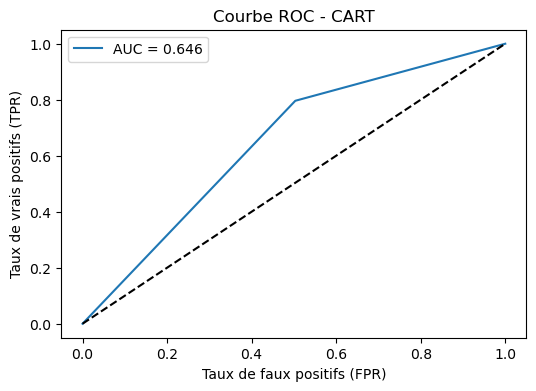

Accuracy  : 0.713
Précision : 0.804
Rappel    : 0.796
Score final = 0.759

Entraînement du modèle : KNN

Matrice de confusion pour KNN :

[[ 270  338]
 [ 212 1368]]


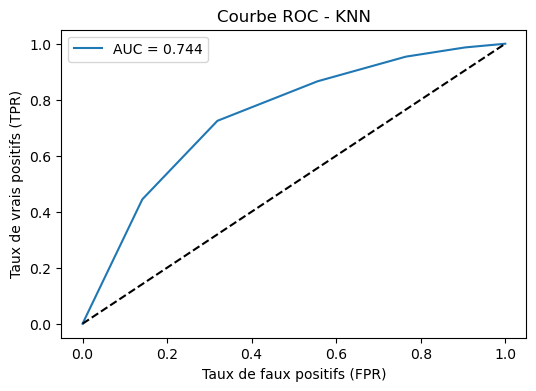

Accuracy  : 0.749
Précision : 0.802
Rappel    : 0.866
Score final = 0.807

Entraînement du modèle : MLP

Matrice de confusion pour MLP :

[[ 354  254]
 [ 278 1302]]


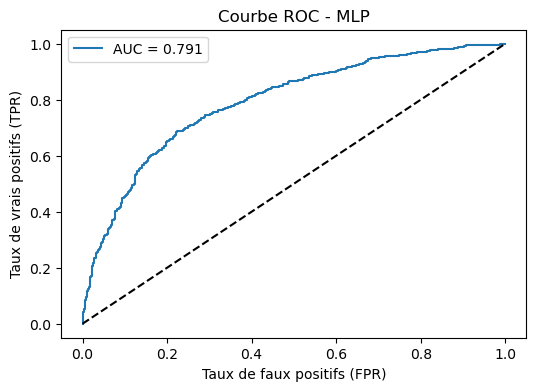

Accuracy  : 0.757
Précision : 0.837
Rappel    : 0.824
Score final = 0.797

##################################################
Meilleur modèle : KNN avec un score de 0.807
##################################################

--- Comparaison des scores ---
Avant normalisation (KNN) : 0.782
Après normalisation (KNN) : 0.807


In [9]:
from sklearn.preprocessing import StandardScaler

# 1. On initialise l'outil de normalisation
scaler = StandardScaler()

# 2. IMPORTANT : On apprend (fit) et on transforme le TRAIN
# Le scaler calcule la moyenne et l'écart-type juste sur X_train
X_train_scaled = scaler.fit_transform(X_train)

# 3. On applique (transform) la transformation sur le TEST
# On utilise les moyennes calculées sur le train. On ne refait PAS de fit !
X_test_scaled = scaler.transform(X_test)

# 4. On relance la compétition entre les algorithmes avec ces nouvelles données
print("\n" + "*"*50)
print("RÉSULTATS APRÈS NORMALISATION (StandardScaler)")
print("*"*50)

# Note : On passe X_train_scaled et X_test_scaled à ta fonction
best_model_scaled, scores_scaled = run_classifiers_train_test(clé, X_train_scaled, X_test_scaled, y_train, y_test)

# 5. Petite comparaison visuelle
print("\n--- Comparaison des scores ---")
print(f"Avant normalisation (KNN) : {scores.get('KNN', 'N/A'):.3f}") 
print(f"Après normalisation (KNN) : {scores_scaled.get('KNN', 'N/A'):.3f}")

Variables avant : 13
Variables après : 16 (On attend +3 variables)

**************************************************
RÉSULTATS AVEC NORMALISATION + ACP (Concaténation)
**************************************************

Entraînement du modèle : CART

Matrice de confusion pour CART :

[[ 305  303]
 [ 296 1284]]


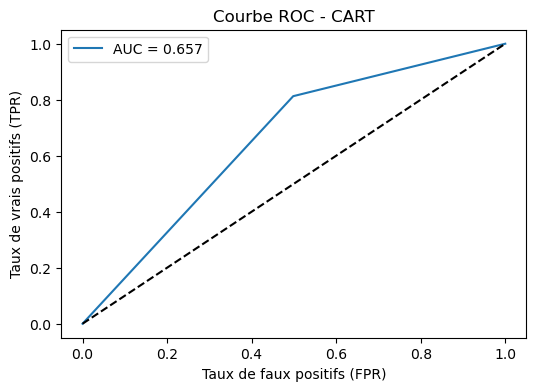

Accuracy  : 0.726
Précision : 0.809
Rappel    : 0.813
Score final = 0.769

Entraînement du modèle : KNN

Matrice de confusion pour KNN :

[[ 258  350]
 [ 206 1374]]


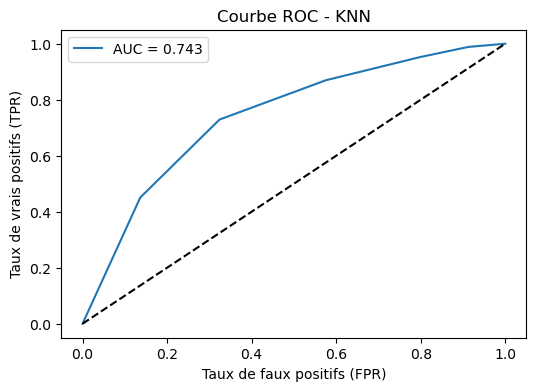

Accuracy  : 0.746
Précision : 0.797
Rappel    : 0.870
Score final = 0.808

Entraînement du modèle : MLP

Matrice de confusion pour MLP :

[[ 339  269]
 [ 249 1331]]


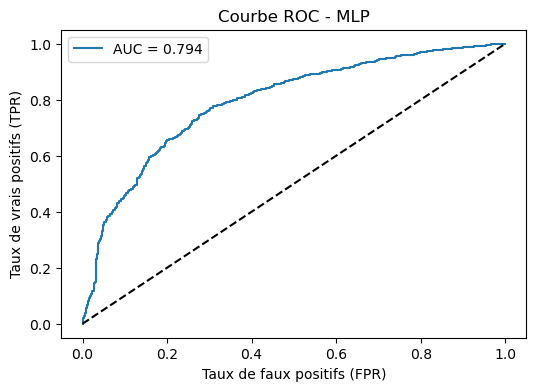

Accuracy  : 0.763
Précision : 0.832
Rappel    : 0.842
Score final = 0.803

##################################################
Meilleur modèle : KNN avec un score de 0.808
##################################################

BILAN DES SCORES (Exemple sur ton meilleur algo)
1. Données Brutes       : 0.757
2. Données Normalisées  : 0.759
3. Normalisées + ACP    : 0.769


In [10]:
from sklearn.decomposition import PCA
import numpy as np

# 1. Initialisation de l'ACP
# On demande à l'algorithme de trouver les 3 meilleurs axes de résumé
pca = PCA(n_components=3)

# 2. Apprentissage et Transformation
# Attention : On fit sur le TRAIN normalisé (X_train_scaled)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled) # On applique juste la transformation sur le test

# 3. Concaténation (Enrichissement)
# On colle les 3 colonnes de l'ACP à droite des données normalisées existantes
# axis=1 signifie "ajouter en colonnes"
X_train_combined = np.concatenate((X_train_scaled, X_train_pca), axis=1)
X_test_combined = np.concatenate((X_test_scaled, X_test_pca), axis=1)

# Petit check pour voir si ça a marché
print(f"Variables avant : {X_train_scaled.shape[1]}")
print(f"Variables après : {X_train_combined.shape[1]} (On attend +3 variables)")

# 4. Lancement des classifieurs sur ce nouveau jeu de données "Boosté"
print("\n" + "*"*50)
print("RÉSULTATS AVEC NORMALISATION + ACP (Concaténation)")
print("*"*50)

best_model_pca, scores_pca = run_classifiers_train_test(clé, X_train_combined, X_test_combined, y_train, y_test)

# --- Comparaison Finale pour la prise de décision ---
print("\n" + "="*50)
print("BILAN DES SCORES (Exemple sur ton meilleur algo)")
print("="*50)
# Remplace 'KNN' par le nom de ton meilleur algo si c'en est un autre
algo_name = list(scores.keys())[0] # Prend le premier algo pour l'exemple
print(f"1. Données Brutes       : {scores.get(algo_name, 0):.3f}")
print(f"2. Données Normalisées  : {scores_scaled.get(algo_name, 0):.3f}")
print(f"3. Normalisées + ACP    : {scores_pca.get(algo_name, 0):.3f}")